# NBA Match Outcome Forecast — analysis and visualization notebook
**AMA2233 Data Analytics and Visualization, The Hong Kong Polytechnic University**

This notebook reproduces every model and chart of the project from the processed data in `data/processed/`.
Run it from the `notebooks/` folder (or the repository root) after `pip install -r requirements.txt`.

Contents
1. Data and the leakage-free feature table
2. Exploratory charts
3. Multicollinearity: correlation heatmap, VIF, PCA
4. Rolling-origin cross-validation and hyperparameter choice
5. Model comparison on the held-out 2025-26 season (table, confusion matrix, calibration)
6. Interpreting the model: odds ratios (L2 vs Lasso) and the decision tree
7. Monte Carlo season simulation: conference tables, playoffs, champion

Educational project. The estimates are not betting advice and the project is not affiliated with the NBA.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
from sklearn.calibration import calibration_curve
from sklearn.tree import plot_tree

warnings.filterwarnings("ignore")
ROOT = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))
import train_and_export as T          # model code shared with the website pipeline
import simulate_season as S
from team_meta import TEAMS, TRAIN_SEASONS, TEST_SEASON, CURRENT_SEASON

FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
# Okabe-Ito colour-blind-safe palette (same as the website)
BLUE, ORANGE, TEAL, VERM, SKY, PURPLE, GREY, INK = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#56B4E9", "#CC79A7", "#8a8478", "#1C1916"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10, "axes.titleweight": "bold"})
def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", bbox_inches="tight"); plt.show()

## 1. Data
`games.csv` has one row per regular-season game. Every feature is computed from games played **before** tip-off
(`shift(1)` followed by expanding / rolling means in `scripts/build_features.py`), so there is no leakage.
The split is by time: train on 2021-22 to 2024-25, test on 2025-26, and apply forward to 2026-27.

In [2]:
games = pd.read_csv(ROOT / "data/processed/games.csv", parse_dates=["GAME_DATE"], dtype={"GAME_ID": str})
team_games = pd.read_csv(ROOT / "data/processed/team_games.csv", parse_dates=["GAME_DATE"], dtype={"GAME_ID": str})
FEATURES, LABELS = T.FEATURES, T.FEATURE_LABELS
train = games[games.SEASON.isin(TRAIN_SEASONS)]
test = games[games.SEASON == TEST_SEASON]
current = games[games.SEASON == CURRENT_SEASON]
X_tr, y_tr = train[FEATURES], train.home_win.to_numpy(int)
X_te, y_te = test[FEATURES], test.home_win.to_numpy(int)
print(f"train {len(train)} games | test {len(test)} | 2026-27 so far {len(current)} | {len(FEATURES)} features")
games.groupby("SEASON").agg(games=("home_win", "size"), home_win_rate=("home_win", "mean")).round(3)

train 4920 games | test 1230 | 2026-27 so far 152 | 23 features


,games,home_win_rate
SEASON,,
2021-22,1230,0.544
2022-23,1230,0.580
2023-24,1230,0.543
2024-25,1230,0.544
2025-26,1230,0.554
2026-27,152,0.520


## 2. Exploratory charts

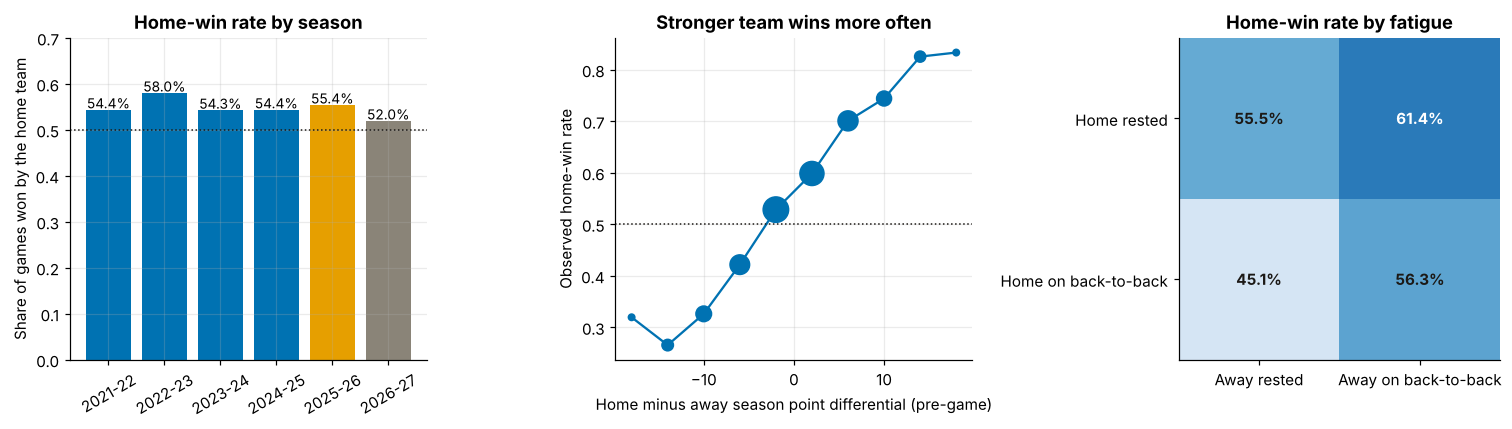

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
hw = games.groupby("SEASON").home_win.mean()
ax[0].bar(hw.index, hw.values, color=[BLUE if s in TRAIN_SEASONS else ORANGE if s == TEST_SEASON else GREY for s in hw.index])
ax[0].axhline(0.5, color=INK, lw=1, ls=":"); ax[0].set_ylim(0, 0.7)
ax[0].set_title("Home-win rate by season"); ax[0].set_ylabel("Share of games won by the home team"); ax[0].tick_params(axis="x", rotation=30)
for i, v in enumerate(hw.values): ax[0].text(i, v + 0.003, f"{v:.1%}", ha="center", fontsize=9)

d = train.assign(diff=train.home_pd - train.away_pd)
bins = pd.cut(d["diff"], np.arange(-20, 21, 4))
g = d.groupby(bins, observed=True).home_win.agg(["mean", "size"])
mid = [iv.mid for iv in g.index]
ax[1].scatter(mid, g["mean"], s=g["size"] / 4, color=BLUE, zorder=3)
ax[1].plot(mid, g["mean"], color=BLUE); ax[1].axhline(0.5, color=INK, lw=1, ls=":")
ax[1].set_title("Stronger team wins more often"); ax[1].set_xlabel("Home minus away season point differential (pre-game)"); ax[1].set_ylabel("Observed home-win rate")

b2b = train.groupby(["home_b2b", "away_b2b"]).home_win.mean().unstack()
im = ax[2].imshow(b2b.values, cmap="Blues", vmin=0.4, vmax=0.7)
ax[2].set_xticks([0, 1], ["Away rested", "Away on back-to-back"]); ax[2].set_yticks([0, 1], ["Home rested", "Home on back-to-back"])
for i in range(2):
    for j in range(2): ax[2].text(j, i, f"{b2b.values[i, j]:.1%}", ha="center", va="center", color="white" if b2b.values[i, j] > 0.58 else INK, fontweight="bold")
ax[2].set_title("Home-win rate by fatigue"); ax[2].grid(False)
save("01_exploration")

## 3. Multicollinearity
Season win %, point differential and their last-10 / last-5 versions all measure team strength.
The heatmap, the variance inflation factors (VIF) and PCA show how much the 23 columns overlap.
A VIF above about 10 means the feature is almost a linear combination of the others.

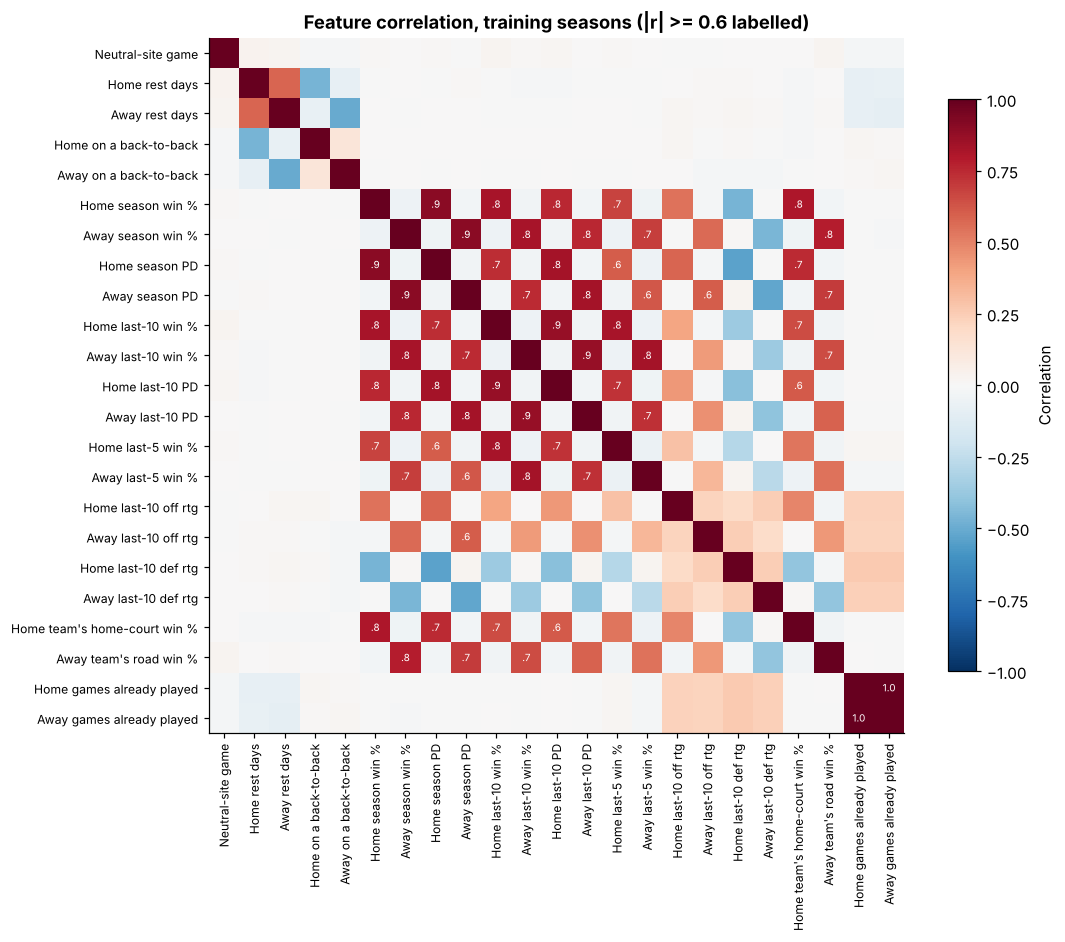

In [4]:
Z = StandardScaler().fit_transform(X_tr)
corr = np.corrcoef(Z.T)
short = [T.FEATURE_LABELS[f].replace(" (pre-game)", "").replace("point differential", "PD").replace("offensive rating", "off rtg").replace("defensive rating", "def rtg") for f in FEATURES]
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(short)), short, rotation=90, fontsize=8); ax.set_yticks(range(len(short)), short, fontsize=8); ax.grid(False)
for i in range(len(short)):
    for j in range(len(short)):
        if i != j and abs(corr[i, j]) >= 0.6: ax.text(j, i, f"{corr[i, j]:.1f}".replace("0.", "."), ha="center", va="center", fontsize=6.5, color="white")
plt.colorbar(im, shrink=0.8, label="Correlation"); ax.set_title("Feature correlation, training seasons (|r| >= 0.6 labelled)")
save("02_correlation_heatmap")

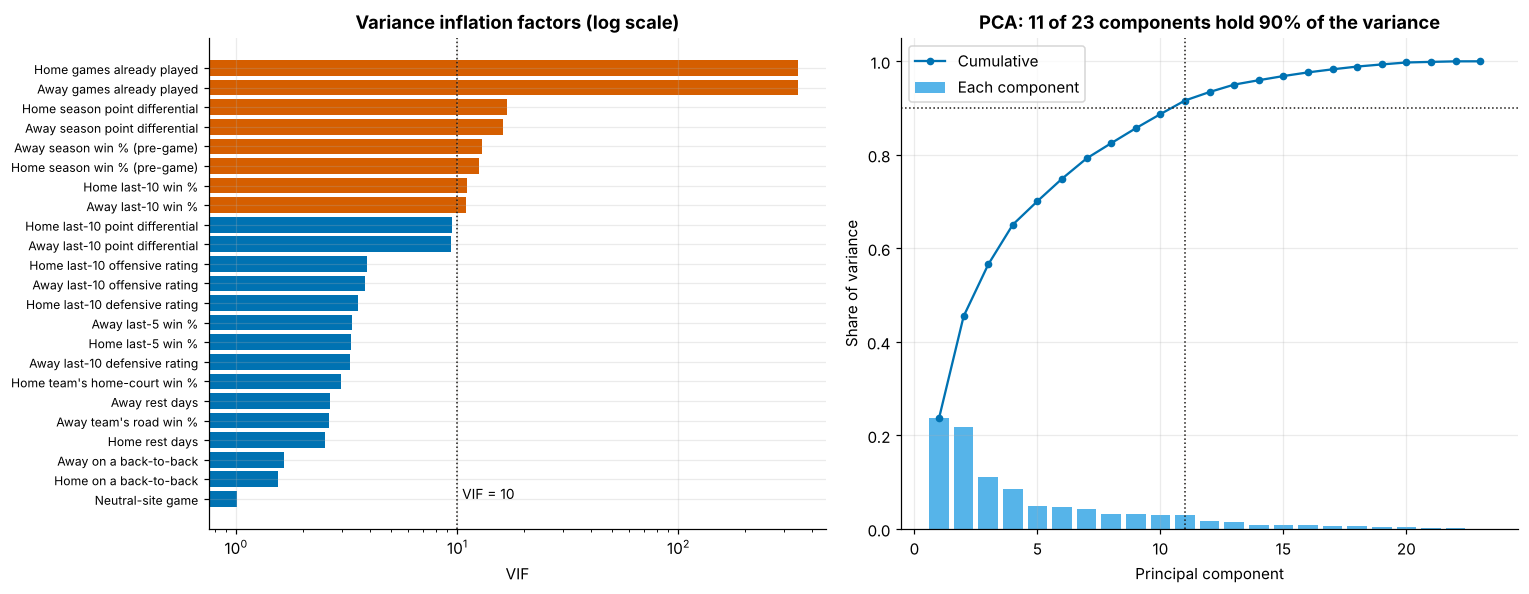

PC1 explains 23.7%; largest PC1 loadings:


Away season win %     0.29
Home season win %    -0.29
Home season PD       -0.29
Away season PD        0.28
Home last-10 win %   -0.28
Away last-10 win %    0.28
Home last-10 PD      -0.28
Away last-10 PD       0.27
dtype: float64

In [5]:
vif = pd.DataFrame(T.vif_table(X_tr)).sort_values("vif")
pca = PCA().fit(Z); evr = pca.explained_variance_ratio_
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ax[0].barh(vif.label, vif.vif, color=[VERM if v > 10 else BLUE for v in vif.vif]); ax[0].set_xscale("log")
ax[0].axvline(10, color=INK, ls=":", lw=1); ax[0].text(10.5, 0, "VIF = 10", fontsize=9)
ax[0].set_title("Variance inflation factors (log scale)"); ax[0].set_xlabel("VIF"); ax[0].tick_params(axis="y", labelsize=8)
k = np.arange(1, len(evr) + 1)
ax[1].bar(k, evr, color=SKY, label="Each component"); ax[1].plot(k, np.cumsum(evr), color=BLUE, marker="o", ms=4, label="Cumulative")
n90 = int(np.searchsorted(np.cumsum(evr), 0.9) + 1)
ax[1].axhline(0.9, color=INK, ls=":", lw=1); ax[1].axvline(n90, color=INK, ls=":", lw=1)
ax[1].set_title(f"PCA: {n90} of {len(evr)} components hold 90% of the variance"); ax[1].set_xlabel("Principal component"); ax[1].set_ylabel("Share of variance"); ax[1].legend()
save("03_vif_pca")
print(f"PC1 explains {evr[0]:.1%}; largest PC1 loadings:")
pd.Series(pca.components_[0], index=short).sort_values(key=abs, ascending=False).head(8).round(2)

## 4. Rolling-origin cross-validation
Random k-fold would let the model train on future games. Instead each fold trains on seasons up to *k* and validates on season *k+1*:

| Fold | Train | Validate |
|---|---|---|
| 1 | 2021-22 | 2022-23 |
| 2 | 2021-22, 2022-23 | 2023-24 |
| 3 | 2021-22 to 2023-24 | 2024-25 |

The score is the mean validation log-loss. The test season 2025-26 is never used here.
For the Lasso we apply the one-standard-error rule: the most regularised `C` whose mean loss is within one standard error of the minimum.

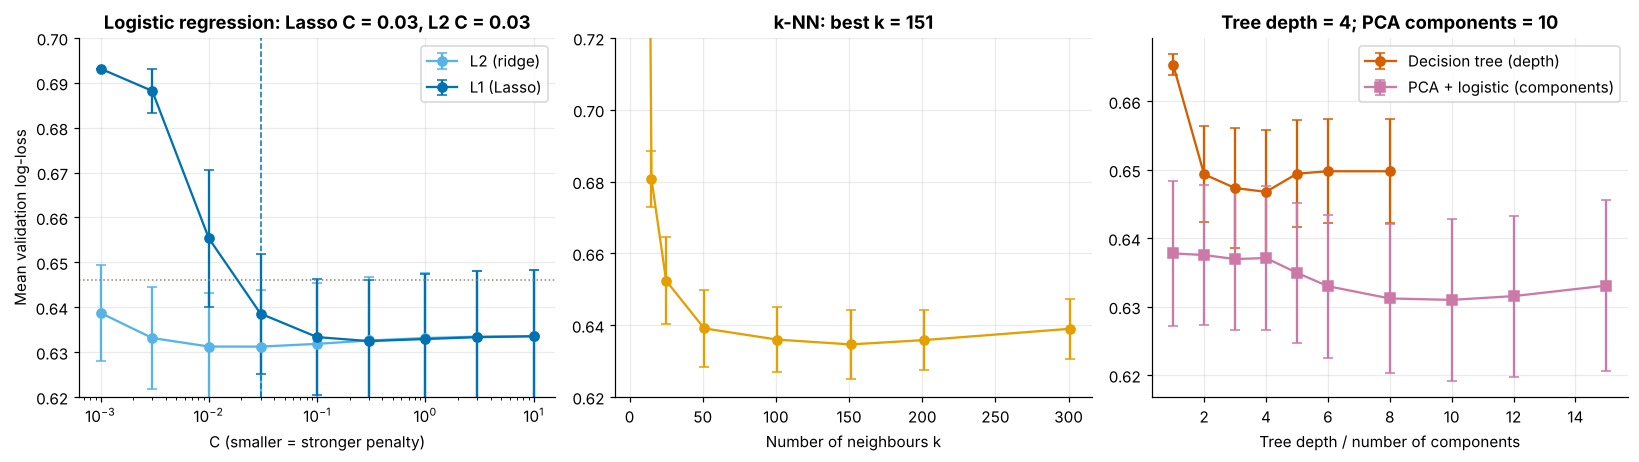

In [6]:
def curve(grid, make):
    rows = []
    for p in grid:
        L = T.rolling_origin_cv(train, make(p)); rows.append((p, np.mean(L), np.std(L, ddof=1) / np.sqrt(len(L))))
    return pd.DataFrame(rows, columns=["param", "mean", "se"])
cv_l1 = curve(T.C_GRID, lambda c: (lambda X, y: T.fit_logistic(X, y, c, "l1")))
cv_l2 = curve(T.C_GRID, lambda c: (lambda X, y: T.fit_logistic(X, y, c, "l2")))
cv_knn = curve((5, 15, 25, 51, 101, 151, 201, 301), lambda k: (lambda X, y: T.fit_knn(X, y, k)))
cv_tree = curve((1, 2, 3, 4, 5, 6, 8), lambda d: (lambda X, y: T.fit_tree(X, y, d, 200)))
cv_pca = curve((1, 2, 3, 4, 5, 6, 8, 10, 12, 15), lambda k: (lambda X, y: T.fit_pca_logistic(X, y, k)))

best = cv_l1.loc[cv_l1["mean"].idxmin()]
C_l1 = cv_l1[cv_l1["mean"] <= best["mean"] + best["se"]].param.min()     # one-standard-error rule
C_l2 = cv_l2.loc[cv_l2["mean"].idxmin(), "param"]
k_knn = int(cv_knn.loc[cv_knn["mean"].idxmin(), "param"]); d_tree = int(cv_tree.loc[cv_tree["mean"].idxmin(), "param"]); k_pca = int(cv_pca.loc[cv_pca["mean"].idxmin(), "param"])

fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for df, name, col in ((cv_l2, "L2 (ridge)", SKY), (cv_l1, "L1 (Lasso)", BLUE)):
    ax[0].errorbar(df.param, df["mean"], yerr=df.se, color=col, marker="o", capsize=3, label=name)
ax[0].axhline(best["mean"] + best["se"], color=GREY, ls=":", lw=1); ax[0].axvline(C_l1, color=BLUE, ls="--", lw=1)
ax[0].set_xscale("log"); ax[0].set_ylim(0.62, 0.70); ax[0].legend()
ax[0].set_title(f"Logistic regression: Lasso C = {C_l1}, L2 C = {C_l2}"); ax[0].set_xlabel("C (smaller = stronger penalty)"); ax[0].set_ylabel("Mean validation log-loss")
ax[1].errorbar(cv_knn.param, cv_knn["mean"], yerr=cv_knn.se, color=ORANGE, marker="o", capsize=3)
ax[1].set_ylim(0.62, 0.72); ax[1].set_title(f"k-NN: best k = {k_knn}"); ax[1].set_xlabel("Number of neighbours k")
ax[2].errorbar(cv_tree.param, cv_tree["mean"], yerr=cv_tree.se, color=VERM, marker="o", capsize=3, label="Decision tree (depth)")
ax[2].errorbar(cv_pca.param, cv_pca["mean"], yerr=cv_pca.se, color=PURPLE, marker="s", capsize=3, label="PCA + logistic (components)")
ax[2].set_title(f"Tree depth = {d_tree}; PCA components = {k_pca}"); ax[2].set_xlabel("Tree depth / number of components"); ax[2].legend()
save("04_rolling_origin_cv")

## 5. Model comparison on the held-out 2025-26 season

In [7]:
meta = json.loads((ROOT / "models/model_meta.json").read_text())      # random-forest setting chosen by the same CV in the pipeline
rf_par = meta["selected_hyperparameters"]["random_forest"]
models = {
    "logistic_regression": T.fit_logistic(X_tr, y_tr, C_l1, "l1"),
    "logistic_l2": T.fit_logistic(X_tr, y_tr, C_l2, "l2"),
    "pca_logistic": T.fit_pca_logistic(X_tr, y_tr, k_pca),
    "decision_tree": T.fit_tree(X_tr, y_tr, d_tree, 200),
    "knn": T.fit_knn(X_tr, y_tr, k_knn),
    "naive_bayes": T.fit_nb(X_tr, y_tr),
    "random_forest": T.fit_rf(X_tr, y_tr, rf_par["max_depth"], rf_par["min_samples_leaf"]),
}
probs = {"baseline_home": np.full(len(test), y_tr.mean()), "baseline_winpct": T.winpct_baseline_p(test)}
probs.update({k: m.predict_proba(X_te)[:, 1] for k, m in models.items()})
table = pd.DataFrame({T.MODEL_LABELS[k]: T.metrics_dict(y_te, p) for k, p in probs.items()}).T[["accuracy", "log_loss", "brier"]]
table.sort_values("log_loss").style.format("{:.4f}").background_gradient(subset=["log_loss", "brier"], cmap="Blues_r").background_gradient(subset=["accuracy"], cmap="Blues")

,accuracy,log_loss,brier
Random forest,0.6764,0.5992,0.2058
"Logistic regression (L2, all features)",0.6650,0.6101,0.2105
"Logistic regression (Lasso, L1)",0.6748,0.6103,0.2105
k-nearest neighbours,0.6683,0.6113,0.2114
Decision tree,0.6488,0.6129,0.2126
PCA + logistic regression,0.6642,0.6156,0.2129
Baseline: always home (p = train home-win rate),0.5545,0.6872,0.2470
Baseline: higher pre-game season win %,0.6699,0.7372,0.2224
Gaussian Naive Bayes,0.6764,0.9741,0.2506


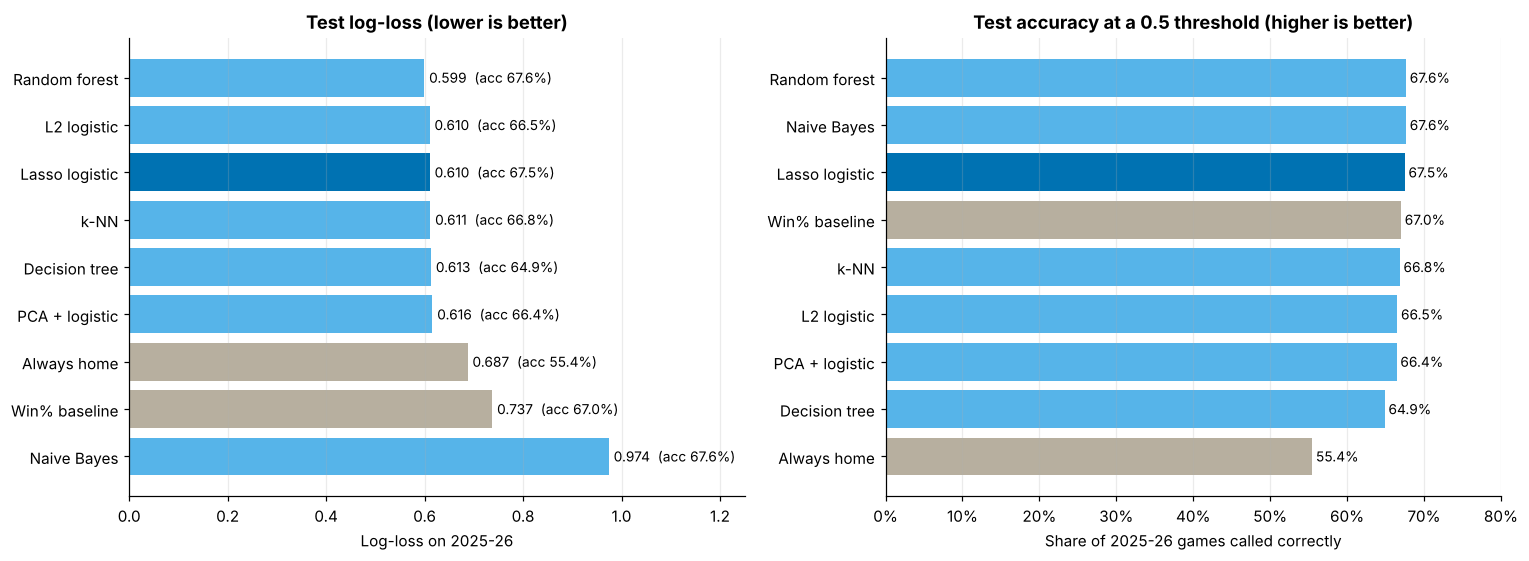

In [8]:
STYLE = {"logistic_regression": ("Lasso logistic", BLUE, "-", 2.8), "logistic_l2": ("L2 logistic", SKY, "-", 1.6), "pca_logistic": ("PCA + logistic", PURPLE, "-", 1.6),
         "decision_tree": ("Decision tree", VERM, "-", 1.6), "knn": ("k-NN", ORANGE, "-", 1.6), "naive_bayes": ("Naive Bayes", INK, "--", 1.6),
         "random_forest": ("Random forest", TEAL, "-", 1.6), "baseline_winpct": ("Win% baseline", GREY, ":", 1.6), "baseline_home": ("Always home", GREY, ":", 1.6)}
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
order = table.assign(k=list(probs)).sort_values("log_loss", ascending=False)
cols = [BLUE if k == "logistic_regression" else "#b7af9f" if k.startswith("baseline") else SKY for k in order.k]
ax[0].barh([STYLE[k][0] for k in order.k], order.log_loss, color=cols)
for i, (ll, acc) in enumerate(zip(order.log_loss, order.accuracy)): ax[0].text(ll + 0.01, i, f"{ll:.3f}  (acc {acc:.1%})", va="center", fontsize=9)
ax[0].set_xlim(0, 1.25); ax[0].set_title("Test log-loss (lower is better)"); ax[0].set_xlabel("Log-loss on 2025-26"); ax[0].grid(axis="y", alpha=0)
acc = order.sort_values("accuracy")
ax[1].barh([STYLE[k][0] for k in acc.k], acc.accuracy, color=[BLUE if k == "logistic_regression" else "#b7af9f" if k.startswith("baseline") else SKY for k in acc.k])
for i, v in enumerate(acc.accuracy): ax[1].text(v + 0.005, i, f"{v:.1%}", va="center", fontsize=9)
ax[1].set_xlim(0, 0.8); ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax[1].grid(axis="y", alpha=0)
ax[1].set_title("Test accuracy at a 0.5 threshold (higher is better)"); ax[1].set_xlabel("Share of 2025-26 games called correctly")
save("05_model_comparison")

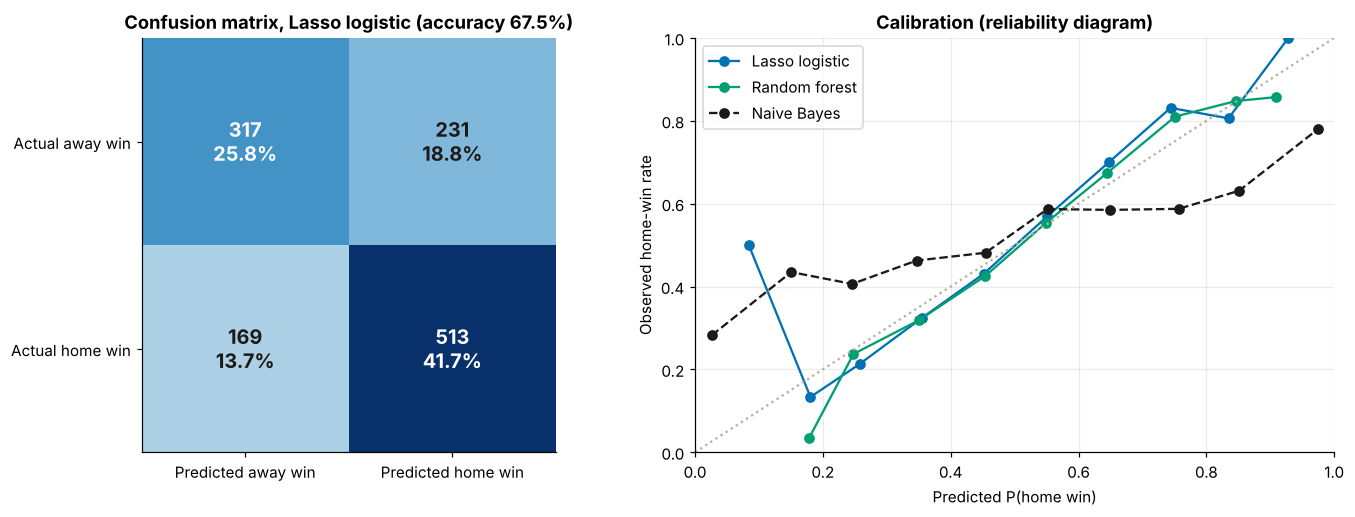

precision 0.690 | recall 0.752 | specificity 0.578


In [9]:
p_lr = probs["logistic_regression"]
cm = confusion_matrix(y_te, (p_lr >= 0.5).astype(int))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].imshow(cm, cmap="Blues", vmin=0); ax[0].grid(False)
ax[0].set_xticks([0, 1], ["Predicted away win", "Predicted home win"]); ax[0].set_yticks([0, 1], ["Actual away win", "Actual home win"])
for i in range(2):
    for j in range(2): ax[0].text(j, i, f"{cm[i, j]}\n{cm[i, j] / cm.sum():.1%}", ha="center", va="center", fontsize=13, fontweight="bold", color="white" if cm[i, j] > cm.max() * 0.55 else INK)
tn, fp, fn, tp = cm.ravel()
ax[0].set_title(f"Confusion matrix, Lasso logistic (accuracy {(tp + tn) / cm.sum():.1%})")
for k in ("logistic_regression", "random_forest", "naive_bayes"):
    frac, mean = calibration_curve(y_te, np.clip(probs[k], 1e-6, 1 - 1e-6), n_bins=10)
    ax[1].plot(mean, frac, marker="o", color=STYLE[k][1], ls=STYLE[k][2], label=STYLE[k][0])
ax[1].plot([0, 1], [0, 1], color="#b7af9f", ls=":"); ax[1].set_xlim(0, 1); ax[1].set_ylim(0, 1)
ax[1].set_title("Calibration (reliability diagram)"); ax[1].set_xlabel("Predicted P(home win)"); ax[1].set_ylabel("Observed home-win rate"); ax[1].legend()
save("06_confusion_calibration")
print(f"precision {tp / (tp + fp):.3f} | recall {tp / (tp + fn):.3f} | specificity {tn / (tn + fp):.3f}")

Naive Bayes has a competitive accuracy but a very poor log-loss: it multiplies the likelihoods of strongly correlated
features as if they were independent, so its probabilities are pushed towards 0 and 1 (the calibration curve is far too flat).

## 6. Interpreting the model
**Why did the old L2 model say that a better last-10 win % lowers the chance of winning?**
Because of the multicollinearity shown in section 3. With all 23 features kept, correlated columns share one effect and individual signs are not identified.
The Lasso sets the redundant coefficients exactly to zero and keeps point differential, which carries the same information more precisely.

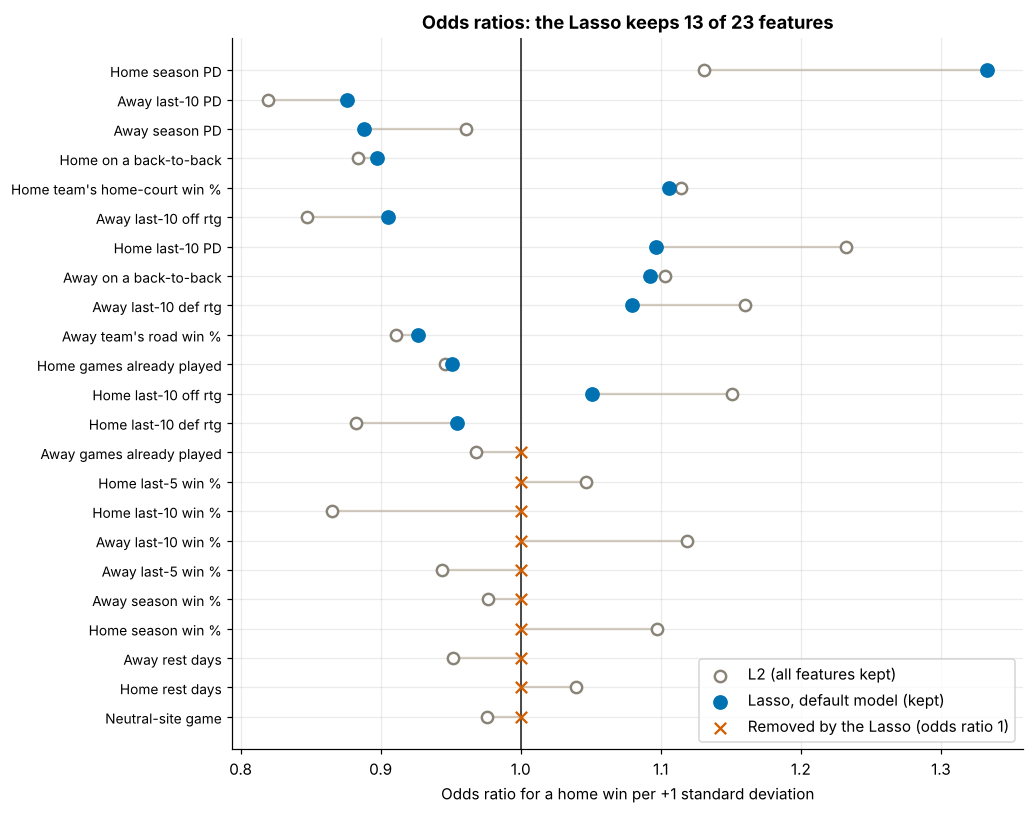

In [10]:
c1 = models["logistic_regression"].named_steps["clf"].coef_[0]; c2 = models["logistic_l2"].named_steps["clf"].coef_[0]
co = pd.DataFrame({"label": short, "lasso": np.exp(c1), "l2": np.exp(c2), "kept": c1 != 0}).sort_values("lasso", key=lambda s: abs(np.log(s))).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9.5, 7.5))
ax.hlines(co.index, co[["lasso", "l2"]].min(axis=1), co[["lasso", "l2"]].max(axis=1), color="#d4cdc0", lw=1.5, zorder=1)
ax.scatter(co.l2, co.index, s=55, facecolor="white", edgecolor=GREY, lw=1.6, label="L2 (all features kept)", zorder=2)
ax.scatter(co.lasso[co.kept], co.index[co.kept], s=75, color=BLUE, label="Lasso, default model (kept)", zorder=3)
ax.scatter(co.lasso[~co.kept], co.index[~co.kept], s=55, color=VERM, marker="x", label="Removed by the Lasso (odds ratio 1)", zorder=3)
ax.axvline(1, color=INK, lw=1); ax.set_yticks(co.index, co.label, fontsize=9)
ax.set_xlabel("Odds ratio for a home win per +1 standard deviation"); ax.set_title(f"Odds ratios: the Lasso keeps {int(co.kept.sum())} of {len(co)} features"); ax.legend(loc="lower right")
save("07_odds_ratios")

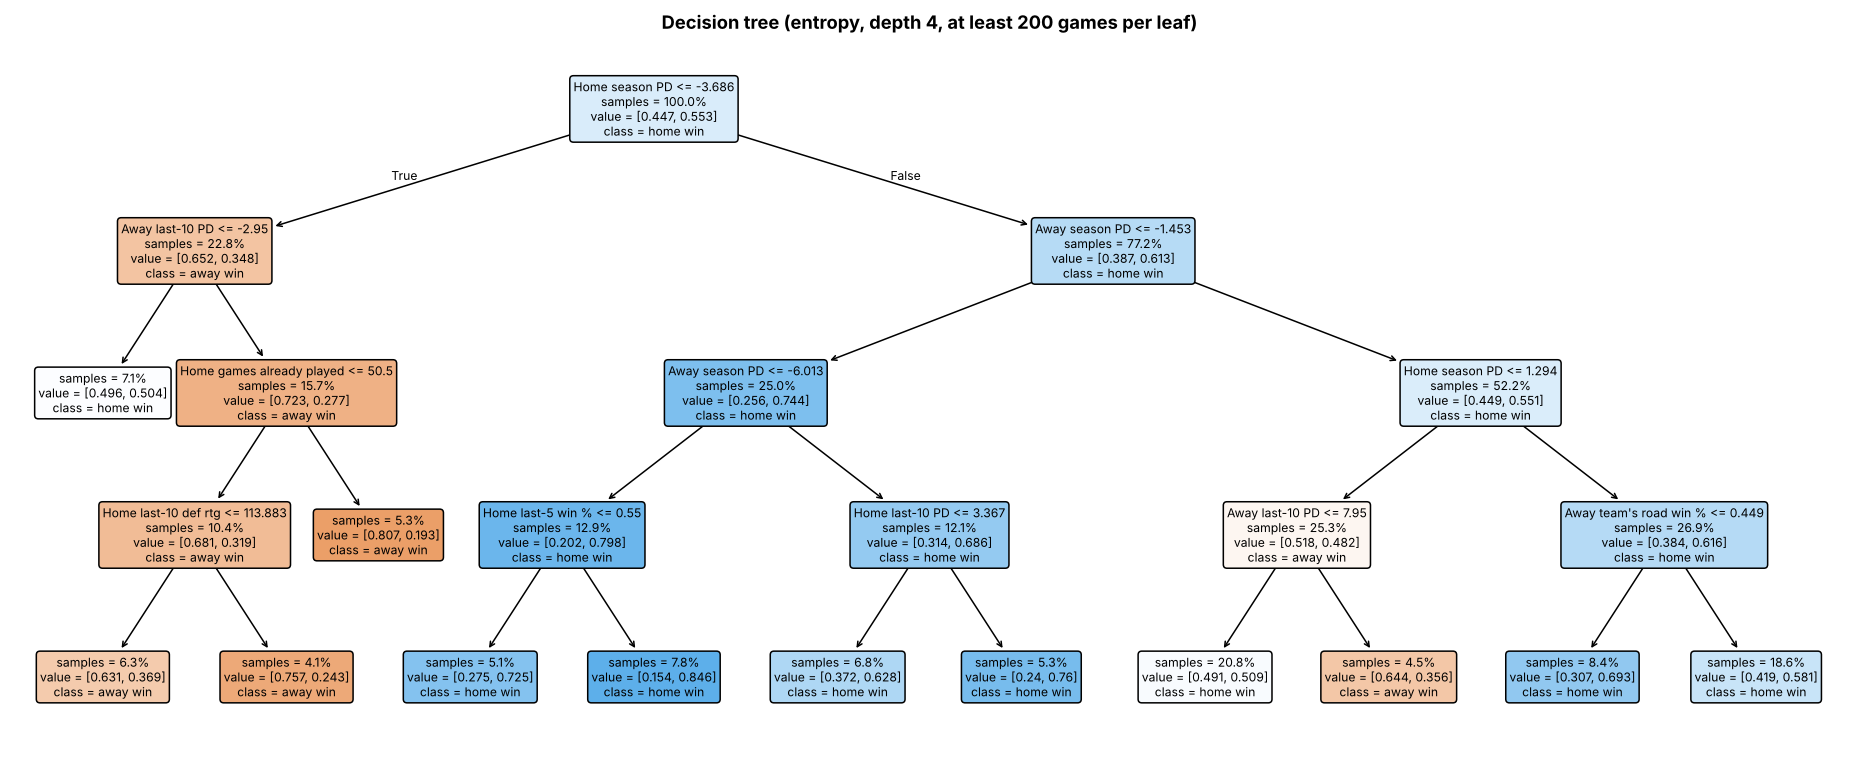

In [11]:
fig, ax = plt.subplots(figsize=(17, 7))
plot_tree(models["decision_tree"], feature_names=short, class_names=["away win", "home win"], filled=True, rounded=True, proportion=True, impurity=False, fontsize=8, ax=ax)
ax.set_title(f"Decision tree (entropy, depth {d_tree}, at least 200 games per leaf)")
save("08_decision_tree")

## 7. Monte Carlo season simulation
Every remaining 2026-27 game is played with the Lasso model's probability. After each simulated game the team's record,
point differential, last-10 form and home/road splits are updated, so later games use the simulated season so far.
Then the play-in (seeds 7-10) and best-of-seven series are simulated. Repeating this 20,000 times gives the probabilities below.
The point margin is drawn as `margin = sigma * (z + e)` with `z = Phi^-1(p)` and `e ~ N(0, 1)`, so that `P(margin > 0) = p`.

In [12]:
lr = models["logistic_regression"]
sigma = S.margin_sigma(lr.predict_proba(X_tr)[:, 1], train.home_PLUS_MINUS.to_numpy(float))
sched = pd.read_csv(ROOT / "data/raw/schedule_2026_27_regular.csv", dtype={"gameId": str})
fc = S.simulate(lr, FEATURES, team_games, sched, sigma)
sim = pd.DataFrame(fc["teams"]).set_index("abbr")
f = fc["favorites"]
print(f"sigma = {sigma:.1f} points | {fc['n_games_simulated']} games simulated x {fc['n_sims']:,} seasons")
print(f"East: {f['east']['name']} {f['east']['p']:.1%} | West: {f['west']['name']} {f['west']['p']:.1%} | Champion: {f['champion']['name']} {f['champion']['p']:.1%}")
def conf_table(conf):
    t = sim.loc[fc["tables"][conf]].copy()
    t.insert(0, "Now", t.current_w.astype(str) + "-" + t.current_l.astype(str))
    t = t.rename(columns={"name": "Team", "proj_w": "Proj. wins", "p_playoffs": "Playoffs", "p_conf_finals": "Conf. finals", "p_conf_champ": f"Win {conf}", "p_champion": "Champion"})
    t = t[["Team", "Now", "Proj. wins", "Playoffs", "Conf. finals", f"Win {conf}", "Champion"]].reset_index(drop=True); t.index += 1
    return t.style.format({"Proj. wins": "{:.1f}", "Playoffs": "{:.1%}", "Conf. finals": "{:.1%}", f"Win {conf}": "{:.1%}", "Champion": "{:.1%}"}).bar(subset=["Playoffs", f"Win {conf}", "Champion"], color="#9ecae1", vmin=0).set_caption(f"{conf}ern Conference: projected final table")
conf_table("East")

sigma = 14.4 points | 1078 games simulated x 20,000 seasons
East: Detroit Pistons 24.1% | West: Minnesota Timberwolves 22.1% | Champion: Minnesota Timberwolves 14.0%


,Team,Now,Proj. wins,Playoffs,Conf. finals,Win East,Champion
1,Detroit Pistons,7-3,52.3,98.6%,41.3%,24.1%,11.5%
2,Boston Celtics,8-2,52.0,98.2%,35.4%,18.7%,8.2%
3,Philadelphia 76ers,9-2,49.7,95.8%,24.2%,11.0%,4.0%
4,Atlanta Hawks,7-5,48.3,94.8%,28.0%,13.8%,5.5%
5,Toronto Raptors,5-5,47.4,92.7%,32.9%,18.4%,8.3%
6,New York Knicks,5-4,42.9,77.3%,11.6%,4.4%,1.4%
7,Cleveland Cavaliers,5-6,42.5,77.0%,12.6%,5.0%,1.6%
8,Washington Wizards,4-7,37.7,48.8%,6.0%,2.3%,0.6%
9,Indiana Pacers,3-8,35.3,35.6%,3.5%,1.1%,0.3%
10,Miami Heat,4-6,34.8,29.7%,1.8%,0.4%,0.1%


In [13]:
conf_table("West")

,Team,Now,Proj. wins,Playoffs,Conf. finals,Win West,Champion
1,Minnesota Timberwolves,8-3,54.2,96.4%,38.2%,22.1%,14.0%
2,Houston Rockets,8-3,53.2,94.5%,31.6%,16.5%,10.2%
3,Los Angeles Lakers,10-2,53.2,93.9%,24.6%,11.8%,6.6%
4,Oklahoma City Thunder,8-2,51.4,89.2%,20.3%,9.2%,5.0%
5,Portland Trail Blazers,6-3,51.3,90.1%,31.0%,17.2%,10.4%
6,San Antonio Spurs,8-2,51.0,88.1%,18.9%,8.1%,4.1%
7,Memphis Grizzlies,7-3,49.9,85.8%,22.1%,10.9%,6.4%
8,Golden State Warriors,7-3,43.1,48.1%,3.9%,1.1%,0.4%
9,Dallas Mavericks,7-4,41.9,41.6%,3.9%,1.4%,0.5%
10,Denver Nuggets,5-4,40.3,32.6%,2.5%,0.8%,0.3%


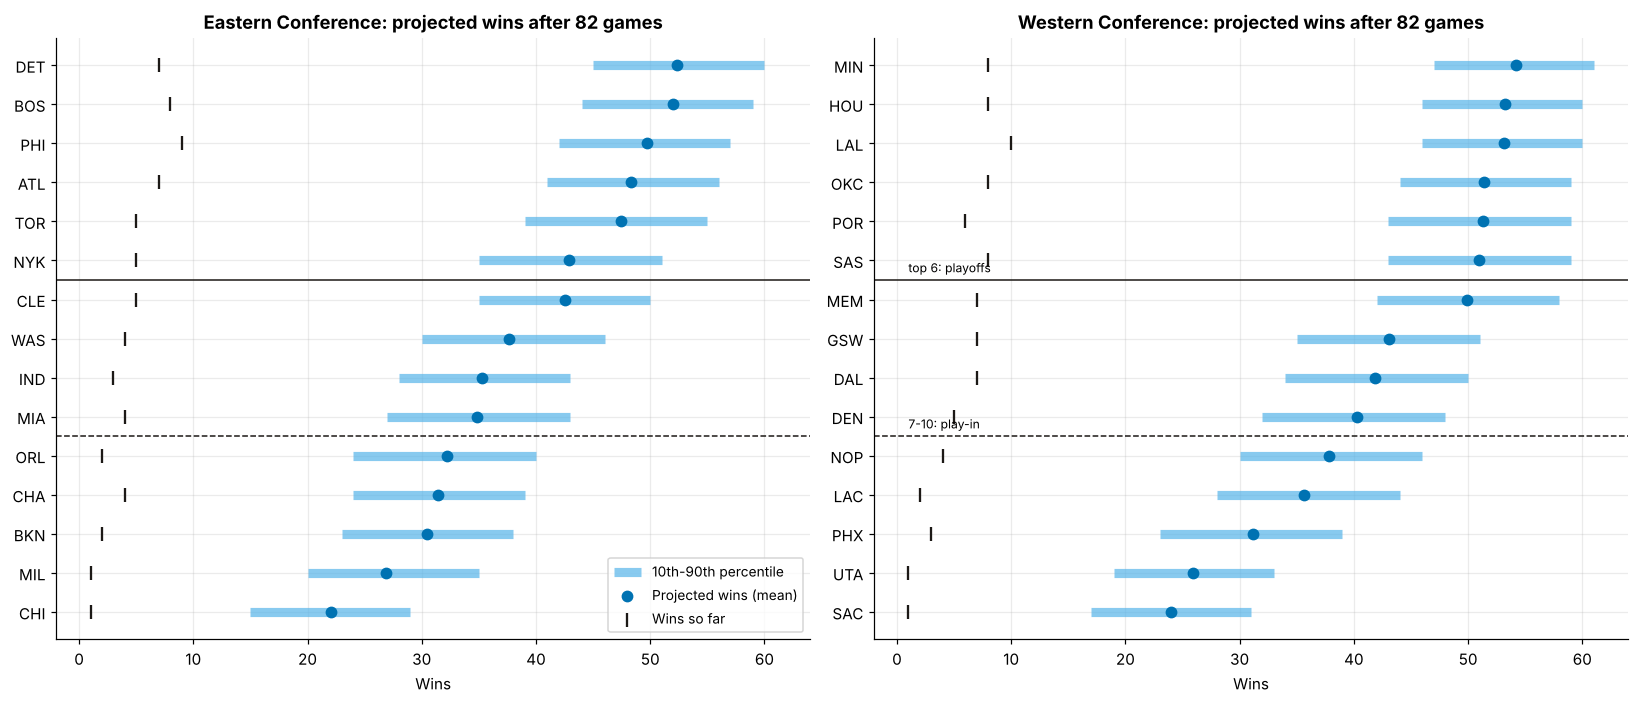

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True)
for a, conf in zip(ax, ("East", "West")):
    t = sim.loc[fc["tables"][conf]].iloc[::-1]
    a.hlines(t.index, t.w_p10, t.w_p90, color=SKY, lw=6, alpha=0.7, label="10th-90th percentile")
    a.scatter(t.proj_w, t.index, color=BLUE, s=45, zorder=3, label="Projected wins (mean)")
    a.scatter(t.current_w, t.index, color=INK, marker="|", s=90, zorder=3, label="Wins so far")
    a.axhline(len(t) - 6.5, color=INK, lw=1); a.axhline(len(t) - 10.5, color=INK, lw=1, ls="--")
    a.set_title(f"{conf}ern Conference: projected wins after 82 games"); a.set_xlabel("Wins")
ax[0].legend(loc="lower right", fontsize=9)
ax[1].text(1, 8.7, "top 6: playoffs", fontsize=8); ax[1].text(1, 4.7, "7-10: play-in", fontsize=8)
save("09_projected_wins")

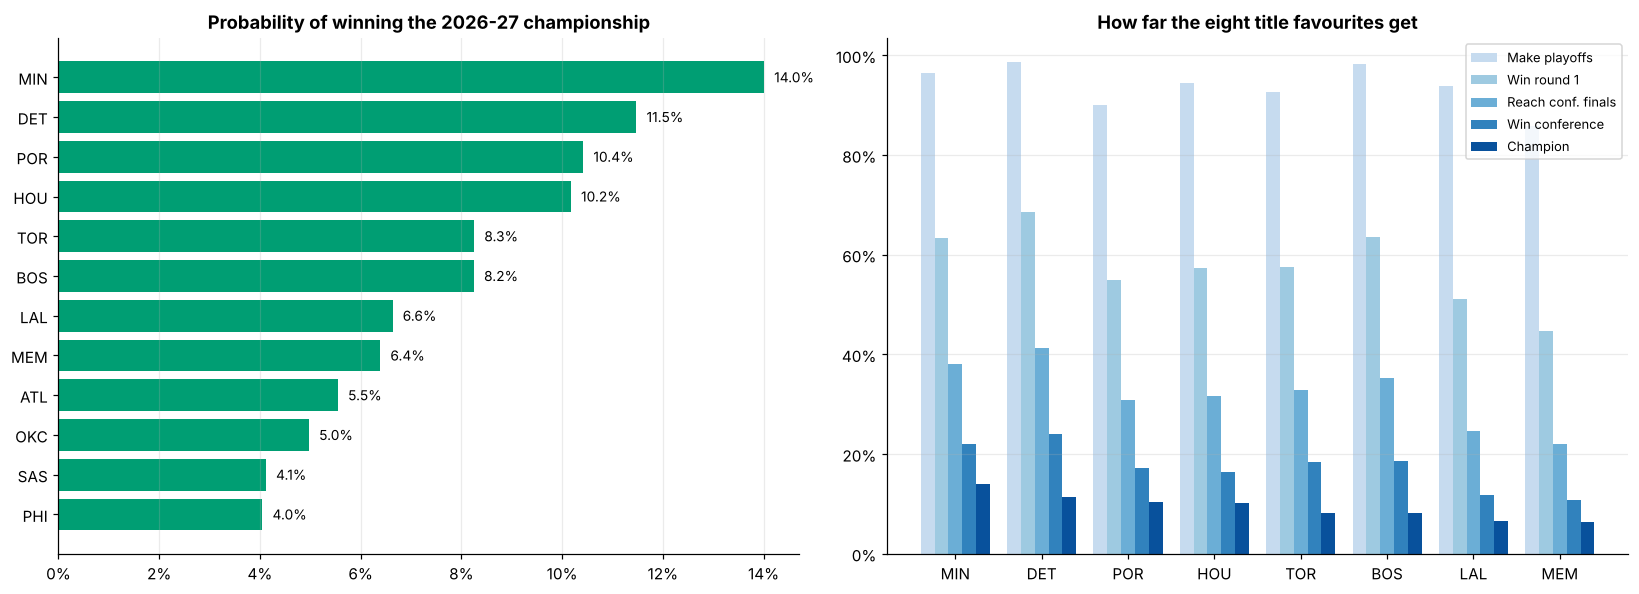

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
top = sim.sort_values("p_champion").tail(12)
ax[0].barh(top.index, top.p_champion, color=TEAL)
for i, v in enumerate(top.p_champion): ax[0].text(v + 0.002, i, f"{v:.1%}", va="center", fontsize=9)
ax[0].set_title("Probability of winning the 2026-27 championship"); ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax[0].grid(axis="y", alpha=0)
stages = [("p_playoffs", "Make playoffs", "#c6dbef"), ("p_round2", "Win round 1", "#9ecae1"), ("p_conf_finals", "Reach conf. finals", "#6baed6"), ("p_conf_champ", "Win conference", "#3182bd"), ("p_champion", "Champion", "#08519c")]
t8 = sim.sort_values("p_champion", ascending=False).head(8); x = np.arange(len(t8)); w = 0.16
for i, (k, name, col) in enumerate(stages): ax[1].bar(x + (i - 2) * w, t8[k], w, color=col, label=name)
ax[1].set_xticks(x, t8.index); ax[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax[1].legend(fontsize=8.5); ax[1].grid(axis="x", alpha=0)
ax[1].set_title("How far the eight title favourites get")
save("10_title_odds")

### Limits of the forecast
* Only about ten games per team have been played, so the simulation leans on a small sample and the percentages will move a lot during the season.
* Injuries, trades, travel and playoff-specific effects are not modelled; last-10 offensive / defensive ratings are held at their current values.
* Standings ties are broken by point differential, not the NBA head-to-head rules. The two NBA Cup-dependent games per team are filled with random same-conference opponents.
* The model accuracy on the held-out season is about 67%, so a single game is far from certain; the simulation propagates exactly that uncertainty.